
# Analisis Data Pengeluaran Operasional untuk Mendukung Efisiensi Anggaran

## Studi Kasus PT Cerdas Mandiri

Notebook ini digunakan untuk menganalisis data pengeluaran operasional perusahaan, mengevaluasi penggunaan anggaran, mengidentifikasi pola pengeluaran, dan memprediksi biaya pada periode berikutnya.

Tahapan analisis meliputi pemahaman masalah bisnis, pemeriksaan dan pembersihan data, analisis deskriptif, analisis diagnostik, pemodelan prediktif, evaluasi model, serta penyusunan rekomendasi berdasarkan hasil analisis.

**Catatan:** Dataset yang digunakan merupakan data simulasi, bukan data keuangan perusahaan yang sebenarnya.


In [1]:

import pandas as pd
import numpy as np

# Agar hasil simulasi dapat direproduksi
np.random.seed(42)

# Periode data: Januari 2024 - Desember 2025
tanggal_bulanan = pd.date_range(
    start="2024-01-01",
    end="2025-12-01",
    freq="MS"
)

departemen = [
    "IT",
    "Keuangan",
    "Pemasaran",
    "Operasional",
    "Umum"
]

kategori = [
    "Listrik",
    "Internet",
    "Transportasi",
    "Perlengkapan Kantor",
    "Pemeliharaan"
]

# Kisaran anggaran per kategori (rupiah)
anggaran_kategori = {
    "Listrik": 4_000_000,
    "Internet": 2_000_000,
    "Transportasi": 5_000_000,
    "Perlengkapan Kantor": 3_000_000,
    "Pemeliharaan": 4_000_000
}

data = []
nomor_transaksi = 1

for bulan in tanggal_bulanan:
    for dept in departemen:
        for kat in kategori:

            anggaran = anggaran_kategori[kat]

            # Variasi biaya normal
            variasi = np.random.uniform(0.65, 1.15)

            # Tren kenaikan biaya pada sebagian kategori
            bulan_ke = (
                (bulan.year - 2024) * 12 + bulan.month - 1
            )

            tren = 1 + (0.008 * bulan_ke)

            # Beberapa kejadian biaya tinggi yang disimulasikan
            lonjakan = 1.0
            if kat == "Transportasi" and bulan.month in [6, 12]:
                lonjakan = np.random.uniform(1.05, 1.30)

            biaya = anggaran * variasi * tren * lonjakan

            data.append({
                "id_transaksi": f"TRX{nomor_transaksi:04d}",
                "tanggal": bulan + pd.Timedelta(
                    days=np.random.randint(0, 25)
                ),
                "departemen": dept,
                "kategori": kat,
                "biaya": round(biaya, 2),
                "anggaran": anggaran
            })

            nomor_transaksi += 1

# Membentuk DataFrame
df = pd.DataFrame(data)

# Memasukkan beberapa masalah data secara sengaja
# 1. Nilai kategori kosong
df.loc[5, "kategori"] = np.nan

# 2. Nilai biaya kosong
df.loc[12, "biaya"] = np.nan

# 3. Duplikat satu transaksi
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

# 4. Satu nilai departemen tidak konsisten
df.loc[20, "departemen"] = " it "

# 5. Satu tanggal tidak valid
df["tanggal"] = df["tanggal"].astype(str)
df.loc[25, "tanggal"] = "tanggal_tidak_valid"

# Simpan dataset mentah
df.to_csv("transaksi_operasional_raw.csv", index=False)

print("Dataset simulasi berhasil dibuat.")
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("\nLima data pertama:")
display(df.head())


Dataset simulasi berhasil dibuat.
Jumlah baris: 601
Jumlah kolom: 6

Lima data pertama:


,id_transaksi,tanggal,departemen,kategori,biaya,anggaran
0,TRX0001,2024-01-15,IT,Listrik,3349080.24,4000000
1,TRX0002,2024-01-21,IT,Internet,2031993.94,2000000
2,TRX0003,2024-01-19,IT,Transportasi,3640046.60,5000000
3,TRX0004,2024-01-11,IT,Perlengkapan Kantor,2099962.37,3000000
4,TRX0005,2024-01-04,IT,Pemeliharaan,4332352.29,4000000


In [2]:

print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data:")
print(df.dtypes)

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all"))

print("\nJumlah nilai kosong:")
display(df.isnull().sum())


Ukuran dataset: (601, 6)

Nama kolom:
['id_transaksi', 'tanggal', 'departemen', 'kategori', 'biaya', 'anggaran']

Tipe data:
id_transaksi     object
tanggal          object
departemen       object
kategori         object
biaya           float64
anggaran          int64
dtype: object

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_transaksi  601 non-null    object 
 1   tanggal       601 non-null    object 
 2   departemen    601 non-null    object 
 3   kategori      600 non-null    object 
 4   biaya         600 non-null    float64
 5   anggaran      601 non-null    int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 28.3+ KB

Statistik deskriptif:


,id_transaksi,tanggal,departemen,kategori,biaya,anggaran
count,601,601,601,600,6.000000e+02,6.010000e+02
unique,600,381,6,5,NaN,NaN
top,TRX0001,2025-02-02,IT,Listrik,NaN,NaN
freq,2,7,121,120,NaN,NaN
mean,NaN,NaN,NaN,NaN,3.539881e+06,3.600666e+06
std,NaN,NaN,NaN,NaN,1.250241e+06,1.019934e+06
min,NaN,NaN,NaN,NaN,1.315966e+06,2.000000e+06
25%,NaN,NaN,NaN,NaN,2.514202e+06,3.000000e+06
50%,NaN,NaN,NaN,NaN,3.483447e+06,4.000000e+06
75%,NaN,NaN,NaN,NaN,4.352335e+06,4.000000e+06



Jumlah nilai kosong:


,0
id_transaksi,0
tanggal,0
departemen,0
kategori,1
biaya,1
anggaran,0


In [3]:

from google.colab import files

files.download("transaksi_operasional_raw.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
print(df.shape)
display(df.head())

(601, 6)


,id_transaksi,tanggal,departemen,kategori,biaya,anggaran
0,TRX0001,2024-01-15,IT,Listrik,3349080.24,4000000
1,TRX0002,2024-01-21,IT,Internet,2031993.94,2000000
2,TRX0003,2024-01-19,IT,Transportasi,3640046.60,5000000
3,TRX0004,2024-01-11,IT,Perlengkapan Kantor,2099962.37,3000000
4,TRX0005,2024-01-04,IT,Pemeliharaan,4332352.29,4000000


In [7]:

print("=== UKURAN DATASET ===")
print(df.shape)

print("\n=== INFORMASI DATASET ===")
df.info()

print("\n=== NILAI KOSONG ===")
display(df.isnull().sum())

print("\n=== JUMLAH DUPLIKAT ===")
print(df.duplicated().sum())

print("\n=== DAFTAR DEPARTEMEN ===")
print(df["departemen"].unique())

print("\n=== DAFTAR KATEGORI ===")
print(df["kategori"].unique())

print("\n=== PEMERIKSAAN TANGGAL ===")
tanggal = pd.to_datetime(df["tanggal"], errors="coerce")
print("Tanggal tidak valid:", tanggal.isna().sum())


=== UKURAN DATASET ===
(601, 6)

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_transaksi  601 non-null    object 
 1   tanggal       601 non-null    object 
 2   departemen    601 non-null    object 
 3   kategori      600 non-null    object 
 4   biaya         600 non-null    float64
 5   anggaran      601 non-null    int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 28.3+ KB

=== NILAI KOSONG ===


,0
id_transaksi,0
tanggal,0
departemen,0
kategori,1
biaya,1
anggaran,0



=== JUMLAH DUPLIKAT ===
1

=== DAFTAR DEPARTEMEN ===
['IT' 'Keuangan' 'Pemasaran' 'Operasional' ' it ' 'Umum']

=== DAFTAR KATEGORI ===
['Listrik' 'Internet' 'Transportasi' 'Perlengkapan Kantor' 'Pemeliharaan'
 nan]

=== PEMERIKSAAN TANGGAL ===
Tanggal tidak valid: 1


In [8]:

# Memeriksa nilai kosong
print("Jumlah nilai kosong per kolom:")
display(df.isnull().sum())

# Memeriksa baris duplikat
print("\nJumlah baris duplikat:", df.duplicated().sum())

# Memeriksa kategori yang tersedia
print("\nDaftar departemen:")
print(df["departemen"].unique())

print("\nDaftar kategori:")
print(df["kategori"].unique())

# Memeriksa tanggal yang tidak dapat dibaca
tanggal_parsed = pd.to_datetime(df["tanggal"], errors="coerce")

print(
    "\nJumlah tanggal tidak valid:",
    tanggal_parsed.isna().sum()
)

# Memeriksa nilai biaya dan anggaran yang negatif
print(
    "\nBiaya negatif:",
    (pd.to_numeric(df["biaya"], errors="coerce") < 0).sum()
)

print(
    "Anggaran negatif:",
    (pd.to_numeric(df["anggaran"], errors="coerce") < 0).sum()
)


Jumlah nilai kosong per kolom:


,0
id_transaksi,0
tanggal,0
departemen,0
kategori,1
biaya,1
anggaran,0



Jumlah baris duplikat: 1

Daftar departemen:
['IT' 'Keuangan' 'Pemasaran' 'Operasional' ' it ' 'Umum']

Daftar kategori:
['Listrik' 'Internet' 'Transportasi' 'Perlengkapan Kantor' 'Pemeliharaan'
 nan]

Jumlah tanggal tidak valid: 1

Biaya negatif: 0
Anggaran negatif: 0


In [9]:

# Salinan dataset mentah
df_clean = df.copy()

print("Jumlah data mentah:", len(df))
print("Jumlah data untuk dibersihkan:", len(df_clean))


Jumlah data mentah: 601
Jumlah data untuk dibersihkan: 601


In [10]:

# Memperbaiki format tanggal
df_clean["tanggal"] = pd.to_datetime(
    df_clean["tanggal"],
    errors="coerce"
)

# Membersihkan spasi dan menyeragamkan penulisan
kolom_teks = ["departemen", "kategori"]

for kolom in kolom_teks:
    df_clean[kolom] = (
        df_clean[kolom]
        .astype("string")
        .str.strip()
    )

# Menyeragamkan kapitalisasi departemen
df_clean["departemen"] = df_clean["departemen"].str.title()

print("Contoh hasil perbaikan:")
display(df_clean.head())


Contoh hasil perbaikan:


,id_transaksi,tanggal,departemen,kategori,biaya,anggaran
0,TRX0001,2024-01-15,It,Listrik,3349080.24,4000000
1,TRX0002,2024-01-21,It,Internet,2031993.94,2000000
2,TRX0003,2024-01-19,It,Transportasi,3640046.60,5000000
3,TRX0004,2024-01-11,It,Perlengkapan Kantor,2099962.37,3000000
4,TRX0005,2024-01-04,It,Pemeliharaan,4332352.29,4000000


In [11]:

# Menyamakan nama departemen sesuai daftar resmi
pemetaan_departemen = {
    "It": "IT",
    "Keuangan": "Keuangan",
    "Pemasaran": "Pemasaran",
    "Operasional": "Operasional",
    "Umum": "Umum"
}

df_clean["departemen"] = df_clean["departemen"].replace(
    pemetaan_departemen
)

print("Departemen setelah dibersihkan:")
print(df_clean["departemen"].unique())


Departemen setelah dibersihkan:
<StringArray>
['IT', 'Keuangan', 'Pemasaran', 'Operasional', 'Umum']
Length: 5, dtype: string


In [12]:

jumlah_sebelum = len(df_clean)

df_clean = df_clean.drop_duplicates()

jumlah_sesudah = len(df_clean)

print("Baris sebelum:", jumlah_sebelum)
print("Baris sesudah:", jumlah_sesudah)
print("Duplikat yang dihapus:", jumlah_sebelum - jumlah_sesudah)


Baris sebelum: 601
Baris sesudah: 600
Duplikat yang dihapus: 1


In [13]:

# Memastikan kolom biaya dan anggaran berbentuk numerik
df_clean["biaya"] = pd.to_numeric(
    df_clean["biaya"], errors="coerce"
)

df_clean["anggaran"] = pd.to_numeric(
    df_clean["anggaran"], errors="coerce"
)

jumlah_sebelum = len(df_clean)

# Menghapus baris yang tidak memiliki informasi penting
kolom_wajib = [
    "tanggal",
    "departemen",
    "kategori",
    "biaya",
    "anggaran"
]

df_clean = df_clean.dropna(subset=kolom_wajib).copy()

print("Baris sebelum penanganan data kosong:", jumlah_sebelum)
print("Baris setelah penanganan data kosong:", len(df_clean))
print("Baris yang dihapus:", jumlah_sebelum - len(df_clean))


Baris sebelum penanganan data kosong: 600
Baris setelah penanganan data kosong: 597
Baris yang dihapus: 3


In [14]:

# Menghitung nilai negatif
biaya_negatif = (df_clean["biaya"] < 0).sum()
anggaran_negatif = (df_clean["anggaran"] < 0).sum()

print("Biaya negatif:", biaya_negatif)
print("Anggaran negatif:", anggaran_negatif)

# Menghapus nilai negatif jika ada,
# sesuai asumsi data transaksi pada studi kasus ini
df_clean = df_clean[
    (df_clean["biaya"] >= 0) &
    (df_clean["anggaran"] >= 0)
].copy()

print("\nUkuran data bersih:", df_clean.shape)


Biaya negatif: 0
Anggaran negatif: 0

Ukuran data bersih: (597, 6)


In [15]:

print("=== HASIL VALIDASI DATA ===")

print("\nUkuran dataset bersih:")
print(df_clean.shape)

print("\nJumlah nilai kosong:")
display(df_clean.isnull().sum())

print("\nJumlah baris duplikat:")
print(df_clean.duplicated().sum())

print("\nTipe data:")
print(df_clean.dtypes)

print("\nRentang tanggal:")
print(df_clean["tanggal"].min(), "sampai", df_clean["tanggal"].max())

print("\nContoh data bersih:")
display(df_clean.head())


=== HASIL VALIDASI DATA ===

Ukuran dataset bersih:
(597, 6)

Jumlah nilai kosong:


,0
id_transaksi,0
tanggal,0
departemen,0
kategori,0
biaya,0
anggaran,0



Jumlah baris duplikat:
0

Tipe data:
id_transaksi            object
tanggal         datetime64[ns]
departemen      string[python]
kategori        string[python]
biaya                  float64
anggaran                 int64
dtype: object

Rentang tanggal:
2024-01-02 00:00:00 sampai 2025-12-25 00:00:00

Contoh data bersih:


,id_transaksi,tanggal,departemen,kategori,biaya,anggaran
0,TRX0001,2024-01-15,IT,Listrik,3349080.24,4000000
1,TRX0002,2024-01-21,IT,Internet,2031993.94,2000000
2,TRX0003,2024-01-19,IT,Transportasi,3640046.60,5000000
3,TRX0004,2024-01-11,IT,Perlengkapan Kantor,2099962.37,3000000
4,TRX0005,2024-01-04,IT,Pemeliharaan,4332352.29,4000000


In [16]:

# Menyimpan data bersih
df_clean.to_csv("transaksi_operasional_clean.csv", index=False)

print("Dataset bersih berhasil disimpan.")

# Mengunduh file ke komputer
from google.colab import files
files.download("transaksi_operasional_clean.csv")


Dataset bersih berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

# Import library yang diperlukan
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Pastikan format data benar
df_clean["tanggal"] = pd.to_datetime(df_clean["tanggal"])
df_clean["biaya"] = pd.to_numeric(df_clean["biaya"])
df_clean["anggaran"] = pd.to_numeric(df_clean["anggaran"])

# Membuat kolom periode bulanan
df_clean["bulan"] = df_clean["tanggal"].dt.to_period("M")

print("Data siap dianalisis.")
print("Jumlah transaksi:", len(df_clean))
display(df_clean.head())


Data siap dianalisis.
Jumlah transaksi: 597


,id_transaksi,tanggal,departemen,kategori,biaya,anggaran,bulan
0,TRX0001,2024-01-15,IT,Listrik,3349080.24,4000000,2024-01
1,TRX0002,2024-01-21,IT,Internet,2031993.94,2000000,2024-01
2,TRX0003,2024-01-19,IT,Transportasi,3640046.60,5000000,2024-01
3,TRX0004,2024-01-11,IT,Perlengkapan Kantor,2099962.37,3000000,2024-01
4,TRX0005,2024-01-04,IT,Pemeliharaan,4332352.29,4000000,2024-01


In [18]:

pengeluaran_bulanan = (
    df_clean.groupby("bulan")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .reset_index()
)

pengeluaran_bulanan["selisih"] = (
    pengeluaran_bulanan["total_biaya"]
    - pengeluaran_bulanan["total_anggaran"]
)

pengeluaran_bulanan["persentase_anggaran"] = (
    pengeluaran_bulanan["total_biaya"]
    / pengeluaran_bulanan["total_anggaran"] * 100
)

# Menampilkan hasil dalam format rupiah
display(pengeluaran_bulanan.round(2))

# Menyimpan hasil
pengeluaran_bulanan.to_csv(
    "ringkasan_pengeluaran_bulanan.csv",
    index=False
)


,bulan,total_biaya,total_anggaran,selisih,persentase_anggaran
0,2024-01,71472700.47,81000000,-9527299.53,88.24
1,2024-02,76424286.67,86000000,-9575713.33,88.87
2,2024-03,84597177.32,90000000,-5402822.68,94.00
3,2024-04,77937688.91,90000000,-12062311.09,86.60
4,2024-05,87612281.29,90000000,-2387718.71,97.35
5,2024-06,86925395.71,90000000,-3074604.29,96.58
6,2024-07,84242229.93,90000000,-5757770.07,93.60
7,2024-08,83229816.14,90000000,-6770183.86,92.48
8,2024-09,81361890.57,90000000,-8638109.43,90.40
9,2024-10,85143872.24,90000000,-4856127.76,94.60


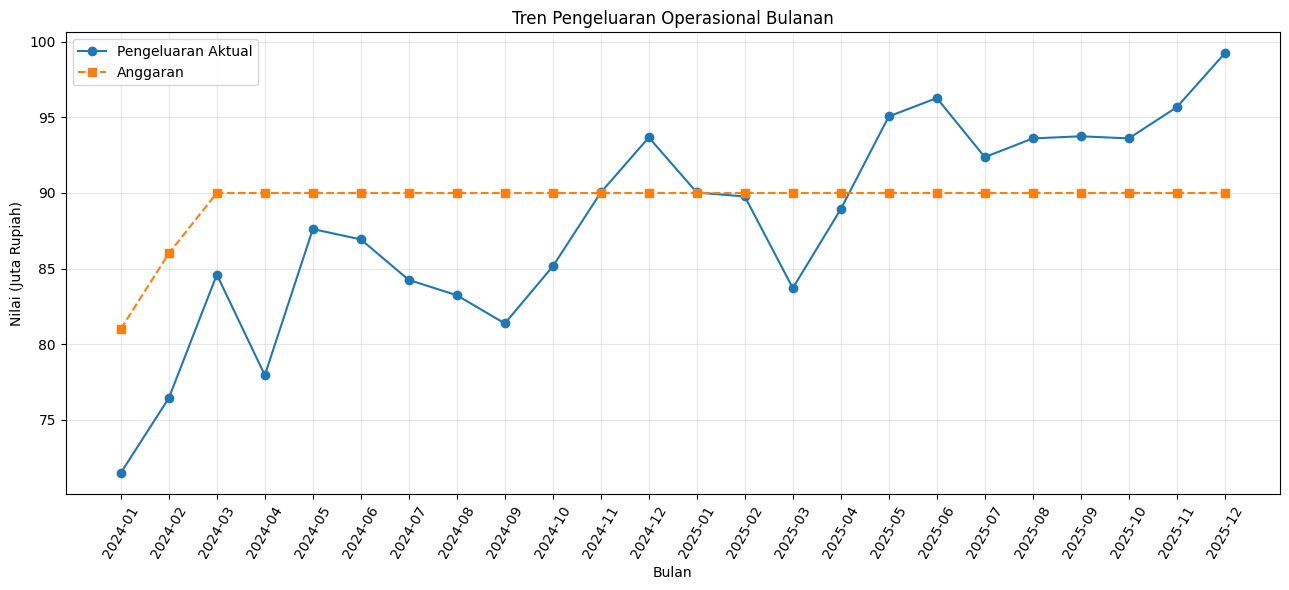

In [19]:

plt.figure(figsize=(13, 6))

plt.plot(
    pengeluaran_bulanan["bulan"].astype(str),
    pengeluaran_bulanan["total_biaya"] / 1_000_000,
    marker="o",
    label="Pengeluaran Aktual"
)

plt.plot(
    pengeluaran_bulanan["bulan"].astype(str),
    pengeluaran_bulanan["total_anggaran"] / 1_000_000,
    marker="s",
    linestyle="--",
    label="Anggaran"
)

plt.title("Tren Pengeluaran Operasional Bulanan")
plt.xlabel("Bulan")
plt.ylabel("Nilai (Juta Rupiah)")
plt.xticks(rotation=60)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("tren_pengeluaran.png", dpi=150)
plt.show()


,kategori,total_biaya,total_anggaran,selisih
0,Transportasi,6.083905e+08,595000000,13390540.45
1,Pemeliharaan,4.697455e+08,480000000,-10254493.51
2,Listrik,4.510716e+08,472000000,-20928372.38
3,Perlengkapan Kantor,3.518776e+08,360000000,-8122419.55
4,Internet,2.336382e+08,240000000,-6361825.61


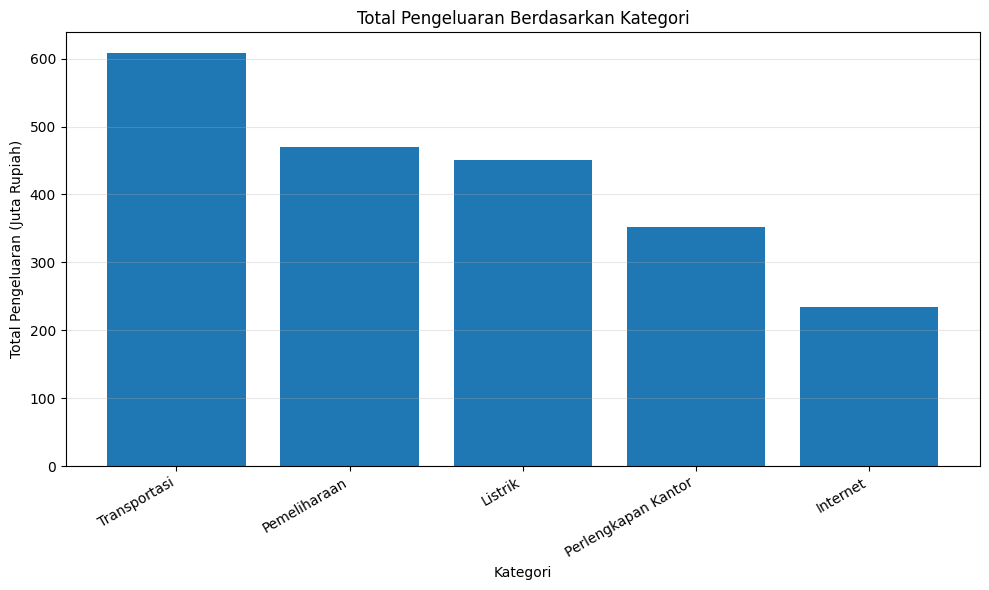

In [20]:

biaya_per_kategori = (
    df_clean.groupby("kategori")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .sort_values("total_biaya", ascending=False)
    .reset_index()
)

biaya_per_kategori["selisih"] = (
    biaya_per_kategori["total_biaya"]
    - biaya_per_kategori["total_anggaran"]
)

display(biaya_per_kategori.round(2))

# Grafik pengeluaran per kategori
plt.figure(figsize=(10, 6))

plt.bar(
    biaya_per_kategori["kategori"],
    biaya_per_kategori["total_biaya"] / 1_000_000
)

plt.title("Total Pengeluaran Berdasarkan Kategori")
plt.xlabel("Kategori")
plt.ylabel("Total Pengeluaran (Juta Rupiah)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("biaya_per_kategori.png", dpi=150)
plt.show()

biaya_per_kategori.to_csv(
    "ringkasan_biaya_per_kategori.csv",
    index=False
)


,departemen,total_biaya,total_anggaran,selisih
0,Keuangan,4.296720e+08,428000000,1672036.46
1,IT,4.264127e+08,432000000,-5587332.22
2,Operasional,4.263580e+08,432000000,-5642002.52
3,Umum,4.233709e+08,428000000,-4629133.28
4,Pemasaran,4.089099e+08,427000000,-18090139.04


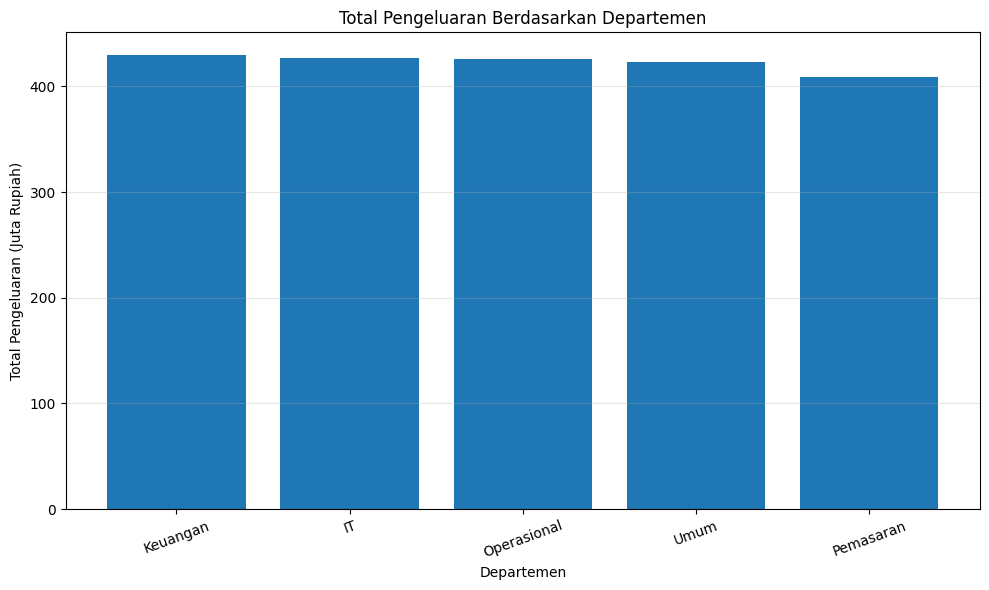

In [21]:

biaya_per_departemen = (
    df_clean.groupby("departemen")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .sort_values("total_biaya", ascending=False)
    .reset_index()
)

biaya_per_departemen["selisih"] = (
    biaya_per_departemen["total_biaya"]
    - biaya_per_departemen["total_anggaran"]
)

display(biaya_per_departemen.round(2))

plt.figure(figsize=(10, 6))

plt.bar(
    biaya_per_departemen["departemen"],
    biaya_per_departemen["total_biaya"] / 1_000_000
)

plt.title("Total Pengeluaran Berdasarkan Departemen")
plt.xlabel("Departemen")
plt.ylabel("Total Pengeluaran (Juta Rupiah)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("biaya_per_departemen.png", dpi=150)
plt.show()

biaya_per_departemen.to_csv(
    "ringkasan_biaya_per_departemen.csv",
    index=False
)


In [22]:

# Ringkasan keseluruhan
total_biaya = df_clean["biaya"].sum()
total_anggaran = df_clean["anggaran"].sum()
selisih_total = total_biaya - total_anggaran

print(f"Total pengeluaran : Rp{total_biaya:,.2f}")
print(f"Total anggaran    : Rp{total_anggaran:,.2f}")
print(f"Selisih           : Rp{selisih_total:,.2f}")

if selisih_total > 0:
    print("Secara keseluruhan, pengeluaran melebihi anggaran.")
else:
    print("Secara keseluruhan, pengeluaran tidak melebihi anggaran.")

# Analisis per kategori
biaya_per_kategori["status_anggaran"] = (
    biaya_per_kategori["selisih"].apply(
        lambda x: "Melebihi anggaran" if x > 0
        else "Sesuai atau di bawah anggaran"
    )
)

display(
    biaya_per_kategori[
        ["kategori", "total_biaya", "total_anggaran",
         "selisih", "status_anggaran"]
    ].round(2)
)


Total pengeluaran : Rp2,114,723,429.40
Total anggaran    : Rp2,147,000,000.00
Selisih           : Rp-32,276,570.60
Secara keseluruhan, pengeluaran tidak melebihi anggaran.


,kategori,total_biaya,total_anggaran,selisih,status_anggaran
0,Transportasi,6.083905e+08,595000000,13390540.45,Melebihi anggaran
1,Pemeliharaan,4.697455e+08,480000000,-10254493.51,Sesuai atau di bawah anggaran
2,Listrik,4.510716e+08,472000000,-20928372.38,Sesuai atau di bawah anggaran
3,Perlengkapan Kantor,3.518776e+08,360000000,-8122419.55,Sesuai atau di bawah anggaran
4,Internet,2.336382e+08,240000000,-6361825.61,Sesuai atau di bawah anggaran


In [25]:

import os

os.makedirs("outputs", exist_ok=True)

pengeluaran_bulanan.to_csv(
    "outputs/ringkasan_pengeluaran_bulanan.csv",
    index=False
)

biaya_per_kategori.to_csv(
    "outputs/ringkasan_biaya_per_kategori.csv",
    index=False
)

biaya_per_departemen.to_csv(
    "outputs/ringkasan_biaya_per_departemen.csv",
    index=False
)

print("Semua ringkasan analisis berhasil disimpan.")


Semua ringkasan analisis berhasil disimpan.


In [26]:

# Membuat ringkasan biaya per kategori
diagnostik_kategori = (
    df_clean.groupby("kategori")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .reset_index()
)

# Menghitung selisih dan persentase kelebihan anggaran
diagnostik_kategori["selisih"] = (
    diagnostik_kategori["total_biaya"]
    - diagnostik_kategori["total_anggaran"]
)

diagnostik_kategori["persentase_selisih"] = (
    diagnostik_kategori["selisih"]
    / diagnostik_kategori["total_anggaran"] * 100
)

# Mengurutkan berdasarkan selisih terbesar
diagnostik_kategori = diagnostik_kategori.sort_values(
    "selisih", ascending=False
)

display(diagnostik_kategori.round(2))


,kategori,total_biaya,total_anggaran,selisih,persentase_selisih
4,Transportasi,6.083905e+08,595000000,13390540.45,2.25
0,Internet,2.336382e+08,240000000,-6361825.61,-2.65
3,Perlengkapan Kantor,3.518776e+08,360000000,-8122419.55,-2.26
2,Pemeliharaan,4.697455e+08,480000000,-10254493.51,-2.14
1,Listrik,4.510716e+08,472000000,-20928372.38,-4.43


In [27]:

diagnostik_departemen = (
    df_clean.groupby(["departemen", "kategori"])
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum"),
        jumlah_transaksi=("id_transaksi", "count")
    )
    .reset_index()
)

diagnostik_departemen["selisih"] = (
    diagnostik_departemen["total_biaya"]
    - diagnostik_departemen["total_anggaran"]
)

diagnostik_departemen["persentase_selisih"] = (
    diagnostik_departemen["selisih"]
    / diagnostik_departemen["total_anggaran"] * 100
)

# Tampilkan kombinasi dengan selisih biaya terbesar
display(
    diagnostik_departemen
    .sort_values("selisih", ascending=False)
    .head(10)
    .round(2)
)


,departemen,kategori,total_biaya,total_anggaran,jumlah_transaksi,selisih,persentase_selisih
24,Umum,Transportasi,1.274258e+08,120000000,24,7425843.30,6.19
4,IT,Transportasi,1.243411e+08,120000000,24,4341072.77,3.62
9,Keuangan,Transportasi,1.230545e+08,120000000,24,3054540.91,2.55
2,IT,Pemeliharaan,9.762192e+07,96000000,24,1621923.54,1.69
10,Operasional,Internet,4.885698e+07,48000000,24,856983.10,1.79
8,Keuangan,Perlengkapan Kantor,7.259107e+07,72000000,24,591069.07,0.82
5,Keuangan,Internet,4.838195e+07,48000000,24,381948.56,0.80
14,Operasional,Transportasi,1.203585e+08,120000000,24,358482.60,0.30
3,IT,Perlengkapan Kantor,7.173384e+07,72000000,24,-266164.17,-0.37
6,Keuangan,Listrik,9.083941e+07,92000000,23,-1160585.11,-1.26


In [28]:

# Membuat ringkasan bulanan
diagnostik_bulanan = (
    df_clean.groupby("bulan")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .reset_index()
)

diagnostik_bulanan["selisih"] = (
    diagnostik_bulanan["total_biaya"]
    - diagnostik_bulanan["total_anggaran"]
)

diagnostik_bulanan["persentase_selisih"] = (
    diagnostik_bulanan["selisih"]
    / diagnostik_bulanan["total_anggaran"] * 100
)

# Bulan dengan kelebihan biaya terbesar
display(
    diagnostik_bulanan
    .sort_values("selisih", ascending=False)
    .head(10)
    .round(2)
)


,bulan,total_biaya,total_anggaran,selisih,persentase_selisih
23,2025-12,99246618.45,90000000,9246618.45,10.27
17,2025-06,96284899.13,90000000,6284899.13,6.98
22,2025-11,95678760.79,90000000,5678760.79,6.31
16,2025-05,95069811.14,90000000,5069811.14,5.63
20,2025-09,93752638.91,90000000,3752638.91,4.17
11,2024-12,93675958.30,90000000,3675958.30,4.08
21,2025-10,93614321.17,90000000,3614321.17,4.02
19,2025-08,93612123.46,90000000,3612123.46,4.01
18,2025-07,92372326.67,90000000,2372326.67,2.64
10,2024-11,90034513.61,90000000,34513.61,0.04


In [29]:

# Pilih bulan dengan selisih terbesar
bulan_tertinggi = diagnostik_bulanan.loc[
    diagnostik_bulanan["selisih"].idxmax(), "bulan"
]

print("Bulan dengan selisih terbesar:", bulan_tertinggi)

# Periksa kategori pada bulan tersebut
data_bulan = df_clean[
    df_clean["bulan"] == bulan_tertinggi
]

diagnostik_bulan_kategori = (
    data_bulan.groupby("kategori")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .reset_index()
)

diagnostik_bulan_kategori["selisih"] = (
    diagnostik_bulan_kategori["total_biaya"]
    - diagnostik_bulan_kategori["total_anggaran"]
)

display(
    diagnostik_bulan_kategori
    .sort_values("selisih", ascending=False)
    .round(2)
)


Bulan dengan selisih terbesar: 2025-12


,kategori,total_biaya,total_anggaran,selisih
4,Transportasi,31812741.35,25000000,6812741.35
2,Pemeliharaan,21459905.46,20000000,1459905.46
3,Perlengkapan Kantor,15849867.48,15000000,849867.48
1,Listrik,20371106.80,20000000,371106.80
0,Internet,9752997.36,10000000,-247002.64


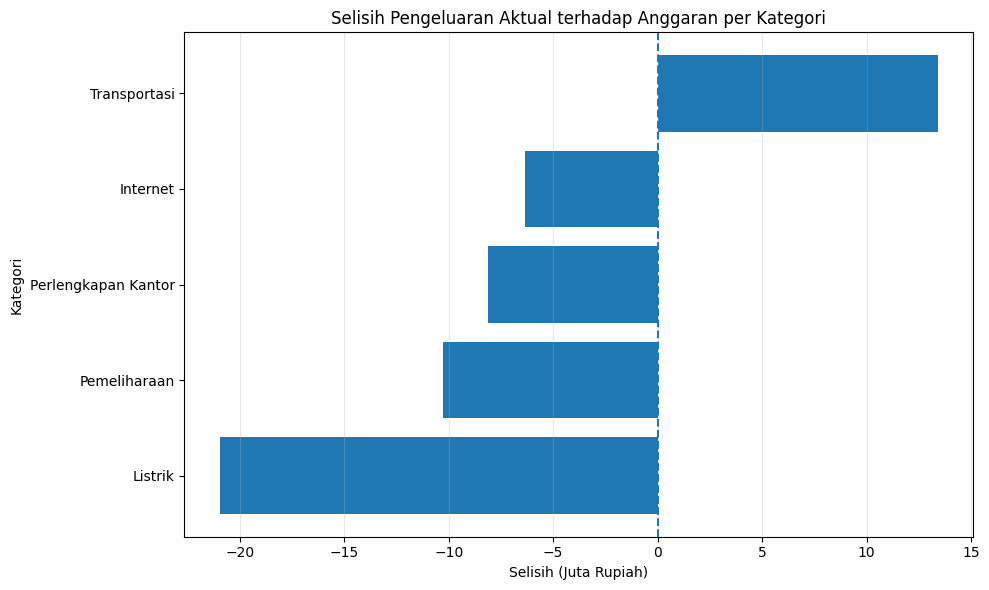

In [30]:

import matplotlib.pyplot as plt

grafik_kategori = diagnostik_kategori.sort_values(
    "selisih", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    grafik_kategori["kategori"],
    grafik_kategori["selisih"] / 1_000_000
)

plt.axvline(0, linestyle="--")

plt.title("Selisih Pengeluaran Aktual terhadap Anggaran per Kategori")
plt.xlabel("Selisih (Juta Rupiah)")
plt.ylabel("Kategori")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("diagnostik_selisih_kategori.png", dpi=150)
plt.show()


In [31]:

kategori_tertinggi = diagnostik_kategori.loc[
    diagnostik_kategori["selisih"].idxmax()
]

kategori_terendah = diagnostik_kategori.loc[
    diagnostik_kategori["selisih"].idxmin()
]

bulan_tertinggi_data = diagnostik_bulanan.loc[
    diagnostik_bulanan["selisih"].idxmax()
]

print("=== RINGKASAN ANALISIS DIAGNOSTIK ===")

print(
    f"\nKategori dengan selisih terbesar: "
    f"{kategori_tertinggi['kategori']}"
)

print(
    f"Selisih: Rp{kategori_tertinggi['selisih']:,.2f}"
)

print(
    f"\nKategori dengan selisih terkecil: "
    f"{kategori_terendah['kategori']}"
)

print(
    f"Selisih: Rp{kategori_terendah['selisih']:,.2f}"
)

print(
    f"\nBulan dengan selisih terbesar: "
    f"{bulan_tertinggi_data['bulan']}"
)

print(
    f"Selisih bulan tersebut: "
    f"Rp{bulan_tertinggi_data['selisih']:,.2f}"
)

print(
    "\nCatatan: hasil ini menunjukkan lokasi dan pola selisih biaya, "
    "bukan membuktikan penyebab operasionalnya."
)


=== RINGKASAN ANALISIS DIAGNOSTIK ===

Kategori dengan selisih terbesar: Transportasi
Selisih: Rp13,390,540.45

Kategori dengan selisih terkecil: Listrik
Selisih: Rp-20,928,372.38

Bulan dengan selisih terbesar: 2025-12
Selisih bulan tersebut: Rp9,246,618.45

Catatan: hasil ini menunjukkan lokasi dan pola selisih biaya, bukan membuktikan penyebab operasionalnya.


In [32]:

import os

os.makedirs("outputs", exist_ok=True)

diagnostik_kategori.to_csv(
    "outputs/diagnostik_kategori.csv", index=False
)

diagnostik_departemen.to_csv(
    "outputs/diagnostik_departemen_kategori.csv", index=False
)

diagnostik_bulanan.to_csv(
    "outputs/diagnostik_bulanan.csv", index=False
)

print("Hasil analisis diagnostik berhasil disimpan.")


Hasil analisis diagnostik berhasil disimpan.


In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Menghitung total pengeluaran per bulan
data_prediksi = (
    df_clean.groupby("bulan")
    .agg(
        total_biaya=("biaya", "sum"),
        total_anggaran=("anggaran", "sum")
    )
    .reset_index()
    .sort_values("bulan")
    .reset_index(drop=True)
)

# Mengubah periode menjadi tanggal awal bulan
data_prediksi["tanggal"] = data_prediksi["bulan"].dt.to_timestamp()

# Membuat fitur urutan waktu
data_prediksi["indeks_bulan"] = np.arange(len(data_prediksi))

print("Jumlah periode:", len(data_prediksi))
display(data_prediksi.head())
display(data_prediksi.tail())


Jumlah periode: 24


,bulan,total_biaya,total_anggaran,tanggal,indeks_bulan
0,2024-01,71472700.47,81000000,2024-01-01,0
1,2024-02,76424286.67,86000000,2024-02-01,1
2,2024-03,84597177.32,90000000,2024-03-01,2
3,2024-04,77937688.91,90000000,2024-04-01,3
4,2024-05,87612281.29,90000000,2024-05-01,4


,bulan,total_biaya,total_anggaran,tanggal,indeks_bulan
19,2025-08,93612123.46,90000000,2025-08-01,19
20,2025-09,93752638.91,90000000,2025-09-01,20
21,2025-10,93614321.17,90000000,2025-10-01,21
22,2025-11,95678760.79,90000000,2025-11-01,22
23,2025-12,99246618.45,90000000,2025-12-01,23


In [34]:

# Memastikan data cukup untuk pelatihan dan pengujian
if len(data_prediksi) < 6:
    raise ValueError(
        "Data bulanan terlalu sedikit untuk evaluasi yang layak."
    )

# Menggunakan sekitar 80% periode awal untuk pelatihan
batas = int(len(data_prediksi) * 0.8)

train = data_prediksi.iloc[:batas].copy()
test = data_prediksi.iloc[batas:].copy()

X_train = train[["indeks_bulan"]]
y_train = train["total_biaya"]

X_test = test[["indeks_bulan"]]
y_test = test["total_biaya"]

print("Periode pelatihan:", len(train), "bulan")
print("Periode pengujian:", len(test), "bulan")
print("Akhir periode pelatihan:", train["bulan"].iloc[-1])
print("Awal periode pengujian:", test["bulan"].iloc[0])


Periode pelatihan: 19 bulan
Periode pengujian: 5 bulan
Akhir periode pelatihan: 2025-07
Awal periode pengujian: 2025-08


In [35]:

from sklearn.linear_model import LinearRegression

# Membuat dan melatih model
model = LinearRegression()
model.fit(X_train, y_train)

# Memprediksi periode pengujian
prediksi_model = model.predict(X_test)

# Menghindari nilai negatif untuk kebutuhan estimasi biaya
prediksi_model = np.maximum(prediksi_model, 0)

print("Model regresi linear berhasil dilatih.")
print("Koefisien:", model.coef_[0])
print("Intercept:", model.intercept_)


Model regresi linear berhasil dilatih.
Koefisien: 921073.9704035091
Intercept: 77963964.08847368


In [36]:

from sklearn.metrics import mean_absolute_error

hasil_uji = test[["bulan", "total_biaya"]].copy()

hasil_uji["prediksi_regresi"] = prediksi_model

# Baseline: prediksi sama dengan pengeluaran bulan sebelumnya
hasil_uji["prediksi_baseline"] = (
    data_prediksi["total_biaya"]
    .shift(1)
    .loc[test.index]
    .values
)

# Menghitung MAE
mae_regresi = mean_absolute_error(
    hasil_uji["total_biaya"],
    hasil_uji["prediksi_regresi"]
)

mae_baseline = mean_absolute_error(
    hasil_uji["total_biaya"],
    hasil_uji["prediksi_baseline"]
)

print(f"MAE Regresi Linear: Rp{mae_regresi:,.2f}")
print(f"MAE Baseline:       Rp{mae_baseline:,.2f}")

display(hasil_uji.round(2))


MAE Regresi Linear: Rp2,164,806.13
MAE Baseline:       Rp1,430,185.45


,bulan,total_biaya,prediksi_regresi,prediksi_baseline
19,2025-08,93612123.46,95464369.53,92372326.67
20,2025-09,93752638.91,96385443.50,93612123.46
21,2025-10,93614321.17,97306517.47,93752638.91
22,2025-11,95678760.79,98227591.44,93614321.17
23,2025-12,99246618.45,99148665.41,95678760.79


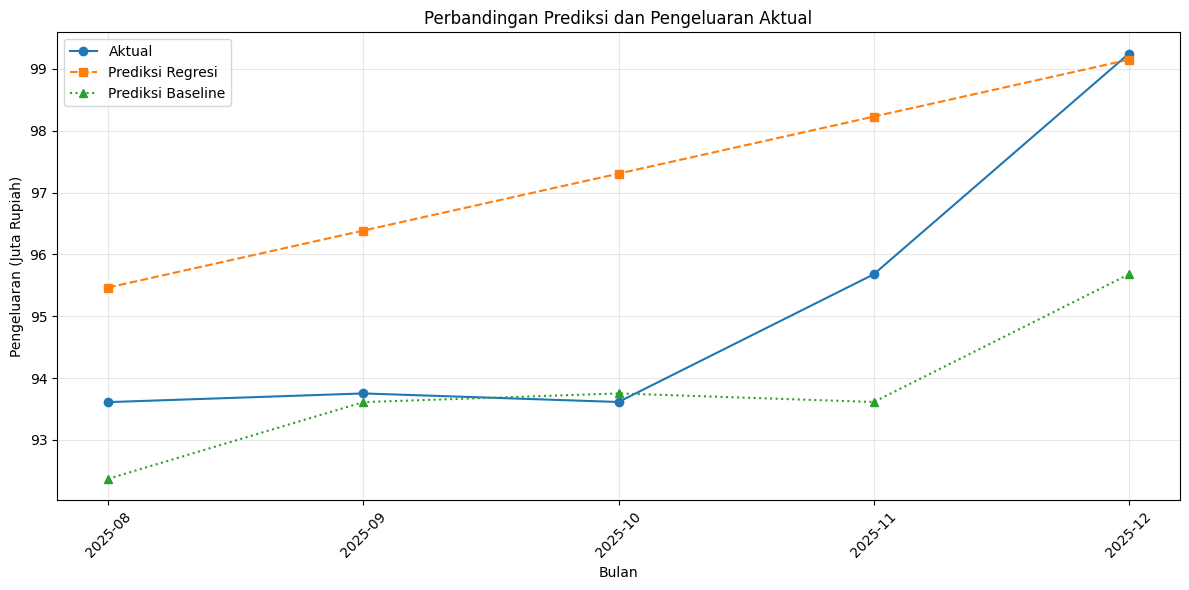

In [37]:

plt.figure(figsize=(12, 6))

bulan_uji = hasil_uji["bulan"].astype(str)

plt.plot(
    bulan_uji,
    hasil_uji["total_biaya"] / 1_000_000,
    marker="o",
    label="Aktual"
)

plt.plot(
    bulan_uji,
    hasil_uji["prediksi_regresi"] / 1_000_000,
    marker="s",
    linestyle="--",
    label="Prediksi Regresi"
)

plt.plot(
    bulan_uji,
    hasil_uji["prediksi_baseline"] / 1_000_000,
    marker="^",
    linestyle=":",
    label="Prediksi Baseline"
)

plt.title("Perbandingan Prediksi dan Pengeluaran Aktual")
plt.xlabel("Bulan")
plt.ylabel("Pengeluaran (Juta Rupiah)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("perbandingan_prediksi.png", dpi=150)
plt.show()


In [38]:

# Melatih model final menggunakan seluruh data historis
model_final = LinearRegression()

model_final.fit(
    data_prediksi[["indeks_bulan"]],
    data_prediksi["total_biaya"]
)

# Menentukan bulan berikutnya
indeks_bulan_berikutnya = len(data_prediksi)

prediksi_bulan_depan = model_final.predict(
    pd.DataFrame({
        "indeks_bulan": [indeks_bulan_berikutnya]
    })
)[0]

# Membatasi estimasi agar tidak negatif
prediksi_bulan_depan = max(0, prediksi_bulan_depan)

bulan_depan = (
    data_prediksi["bulan"].max() + 1
)

hasil_prediksi_depan = pd.DataFrame({
    "bulan": [str(bulan_depan)],
    "prediksi_pengeluaran": [prediksi_bulan_depan]
})

print("Bulan yang diprediksi:", bulan_depan)
print(
    f"Estimasi pengeluaran: "
    f"Rp{prediksi_bulan_depan:,.2f}"
)

display(hasil_prediksi_depan.round(2))

hasil_prediksi_depan.to_csv(
    "hasil_prediksi_bulan_berikutnya.csv",
    index=False
)


Bulan yang diprediksi: 2026-01
Estimasi pengeluaran: Rp98,572,739.86


,bulan,prediksi_pengeluaran
0,2026-01,98572739.86


In [39]:

import os

os.makedirs("outputs", exist_ok=True)

hasil_uji.to_csv(
    "outputs/evaluasi_prediksi.csv",
    index=False
)

hasil_prediksi_depan.to_csv(
    "outputs/hasil_prediksi_bulan_berikutnya.csv",
    index=False
)

# Menyimpan ringkasan metrik evaluasi
ringkasan_evaluasi = pd.DataFrame({
    "model": ["Regresi Linear", "Baseline Bulan Sebelumnya"],
    "MAE": [mae_regresi, mae_baseline]
})

ringkasan_evaluasi.to_csv(
    "outputs/ringkasan_evaluasi_model.csv",
    index=False
)

print("Hasil evaluasi dan prediksi berhasil disimpan.")


Hasil evaluasi dan prediksi berhasil disimpan.


In [40]:

# Ringkasan pengeluaran
total_biaya = df_clean["biaya"].sum()
total_anggaran = df_clean["anggaran"].sum()
selisih_total = total_biaya - total_anggaran

persentase_penggunaan = (
    total_biaya / total_anggaran * 100
    if total_anggaran != 0 else 0
)

# Kategori dengan selisih anggaran terbesar
kategori_tertinggi = diagnostik_kategori.loc[
    diagnostik_kategori["selisih"].idxmax()
]

# Bulan dengan selisih anggaran terbesar
bulan_tertinggi = diagnostik_bulanan.loc[
    diagnostik_bulanan["selisih"].idxmax()
]

print("=== RINGKASAN ANALISIS PENGELUARAN ===")
print(f"Jumlah transaksi      : {len(df_clean)}")
print(f"Total pengeluaran     : Rp{total_biaya:,.2f}")
print(f"Total anggaran        : Rp{total_anggaran:,.2f}")
print(f"Selisih biaya         : Rp{selisih_total:,.2f}")
print(f"Penggunaan anggaran   : {persentase_penggunaan:.2f}%")

print("\n=== TEMUAN UTAMA ===")
print(
    f"Kategori dengan selisih terbesar: "
    f"{kategori_tertinggi['kategori']}"
)
print(
    f"Selisih kategori: "
    f"Rp{kategori_tertinggi['selisih']:,.2f}"
)
print(f"Bulan dengan selisih terbesar: {bulan_tertinggi['bulan']}")
print(
    f"Selisih bulan: Rp{bulan_tertinggi['selisih']:,.2f}"
)


=== RINGKASAN ANALISIS PENGELUARAN ===
Jumlah transaksi      : 597
Total pengeluaran     : Rp2,114,723,429.40
Total anggaran        : Rp2,147,000,000.00
Selisih biaya         : Rp-32,276,570.60
Penggunaan anggaran   : 98.50%

=== TEMUAN UTAMA ===
Kategori dengan selisih terbesar: Transportasi
Selisih kategori: Rp13,390,540.45
Bulan dengan selisih terbesar: 2025-12
Selisih bulan: Rp9,246,618.45


In [41]:

# Membandingkan performa model
display(ringkasan_evaluasi)

if mae_regresi < mae_baseline:
    print(
        "Interpretasi: Regresi linear memiliki MAE lebih rendah "
        "daripada baseline pada data pengujian."
    )
elif mae_regresi > mae_baseline:
    print(
        "Interpretasi: Regresi linear memiliki MAE lebih tinggi "
        "daripada baseline. Model belum mengungguli metode sederhana."
    )
else:
    print(
        "Interpretasi: Kedua metode menghasilkan MAE yang sama "
        "pada periode pengujian."
    )

print(
    f"\nEstimasi pengeluaran bulan berikutnya: "
    f"Rp{prediksi_bulan_depan:,.2f}"
)


,model,MAE
0,Regresi Linear,2.164806e+06
1,Baseline Bulan Sebelumnya,1.430185e+06


Interpretasi: Regresi linear memiliki MAE lebih tinggi daripada baseline. Model belum mengungguli metode sederhana.

Estimasi pengeluaran bulan berikutnya: Rp98,572,739.86


In [42]:

# Membandingkan performa model
display(ringkasan_evaluasi)

if mae_regresi < mae_baseline:
    print(
        "Interpretasi: Regresi linear memiliki MAE lebih rendah "
        "daripada baseline pada data pengujian."
    )
elif mae_regresi > mae_baseline:
    print(
        "Interpretasi: Regresi linear memiliki MAE lebih tinggi "
        "daripada baseline. Model belum mengungguli metode sederhana."
    )
else:
    print(
        "Interpretasi: Kedua metode menghasilkan MAE yang sama "
        "pada periode pengujian."
    )

print(
    f"\nEstimasi pengeluaran bulan berikutnya: "
    f"Rp{prediksi_bulan_depan:,.2f}"
)


,model,MAE
0,Regresi Linear,2.164806e+06
1,Baseline Bulan Sebelumnya,1.430185e+06


Interpretasi: Regresi linear memiliki MAE lebih tinggi daripada baseline. Model belum mengungguli metode sederhana.

Estimasi pengeluaran bulan berikutnya: Rp98,572,739.86


In [43]:

import os

os.makedirs("outputs", exist_ok=True)

if selisih_total > 0:
    status_anggaran = "Pengeluaran agregat melebihi anggaran."
elif selisih_total < 0:
    status_anggaran = "Pengeluaran agregat di bawah anggaran."
else:
    status_anggaran = "Pengeluaran agregat sama dengan anggaran."

if mae_regresi < mae_baseline:
    status_model = (
        "Regresi linear memiliki MAE lebih rendah daripada baseline "
        "pada periode pengujian."
    )
else:
    status_model = (
        "Regresi linear belum menunjukkan MAE yang lebih rendah "
        "daripada baseline pada periode pengujian."
    )

laporan = f"""
LAPORAN INTERPRETASI ANALISIS PENGELUARAN OPERASIONAL
Studi Kasus: PT Cerdas Mandiri (Data Simulasi)

1. RINGKASAN
Jumlah transaksi bersih: {len(df_clean)}
Total pengeluaran: Rp{total_biaya:,.2f}
Total anggaran: Rp{total_anggaran:,.2f}
Selisih pengeluaran: Rp{selisih_total:,.2f}
Persentase penggunaan anggaran: {persentase_penggunaan:.2f}%

2. TEMUAN DIAGNOSTIK
Kategori dengan selisih terbesar:
{kategori_tertinggi['kategori']}

Selisih kategori:
Rp{kategori_tertinggi['selisih']:,.2f}

Bulan dengan selisih terbesar:
{bulan_tertinggi['bulan']}

Selisih bulan:
Rp{bulan_tertinggi['selisih']:,.2f}

Status anggaran: {status_anggaran}

3. EVALUASI PREDIKSI
MAE regresi linear: Rp{mae_regresi:,.2f}
MAE baseline: Rp{mae_baseline:,.2f}

{status_model}

Estimasi pengeluaran bulan berikutnya:
Rp{prediksi_bulan_depan:,.2f}

4. REKOMENDASI
- Periksa transaksi pada kategori yang memiliki selisih anggaran terbesar.
- Telusuri penyebab kenaikan pengeluaran pada periode yang menonjol.
- Gunakan hasil prediksi sebagai bahan pertimbangan perencanaan anggaran.
- Validasi temuan bersama pihak yang memahami operasional perusahaan.

CATATAN
Data yang digunakan merupakan simulasi. Hasil tidak menggambarkan
kondisi keuangan perusahaan nyata. Prediksi merupakan estimasi dan
perlu dievaluasi sebelum digunakan untuk pengambilan keputusan.
"""

with open(
    "outputs/laporan_interpretasi.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(laporan)

print("Laporan interpretasi berhasil disimpan.")
print(laporan)


Laporan interpretasi berhasil disimpan.

LAPORAN INTERPRETASI ANALISIS PENGELUARAN OPERASIONAL
Studi Kasus: PT Cerdas Mandiri (Data Simulasi)

1. RINGKASAN
Jumlah transaksi bersih: 597
Total pengeluaran: Rp2,114,723,429.40
Total anggaran: Rp2,147,000,000.00
Selisih pengeluaran: Rp-32,276,570.60
Persentase penggunaan anggaran: 98.50%

2. TEMUAN DIAGNOSTIK
Kategori dengan selisih terbesar:
Transportasi

Selisih kategori:
Rp13,390,540.45

Bulan dengan selisih terbesar:
2025-12

Selisih bulan:
Rp9,246,618.45

Status anggaran: Pengeluaran agregat di bawah anggaran.

3. EVALUASI PREDIKSI
MAE regresi linear: Rp2,164,806.13
MAE baseline: Rp1,430,185.45

Regresi linear belum menunjukkan MAE yang lebih rendah daripada baseline pada periode pengujian.

Estimasi pengeluaran bulan berikutnya:
Rp98,572,739.86

4. REKOMENDASI
- Periksa transaksi pada kategori yang memiliki selisih anggaran terbesar.
- Telusuri penyebab kenaikan pengeluaran pada periode yang menonjol.
- Gunakan hasil prediksi sebagai 

In [45]:

# Memeriksa kesiapan hasil analisis

print("=== EVALUASI KESELURUHAN PROYEK ===")

# 1. Kondisi dataset
print("\n1. DATASET")
print("Jumlah transaksi bersih:", len(df_clean))
print("Jumlah nilai kosong:", df_clean.isnull().sum().sum())
print("Jumlah baris duplikat:", df_clean.duplicated().sum())

# 2. Ringkasan pengeluaran
print("\n2. ANALISIS DESKRIPTIF")
print("Total pengeluaran: Rp{:,.2f}".format(
    df_clean["biaya"].sum()
))
print("Total anggaran: Rp{:,.2f}".format(
    df_clean["anggaran"].sum()
))

# 3. Analisis diagnostik
print("\n3. ANALISIS DIAGNOSTIK")
print("Jumlah kategori:", df_clean["kategori"].nunique())
print("Jumlah departemen:", df_clean["departemen"].nunique())

# 4. Evaluasi prediksi
print("\n4. EVALUASI MODEL")
print("MAE Regresi Linear: Rp{:,.2f}".format(mae_regresi))
print("MAE Baseline: Rp{:,.2f}".format(mae_baseline))

if mae_regresi < mae_baseline:
    print("Regresi Linear lebih baik daripada baseline pada data uji.")
elif mae_regresi > mae_baseline:
    print("Baseline lebih baik daripada Regresi Linear pada data uji.")
else:
    print("Kedua metode memiliki MAE yang sama.")

print("\nEvaluasi selesai.")


=== EVALUASI KESELURUHAN PROYEK ===

1. DATASET
Jumlah transaksi bersih: 597
Jumlah nilai kosong: 0
Jumlah baris duplikat: 0

2. ANALISIS DESKRIPTIF
Total pengeluaran: Rp2,114,723,429.40
Total anggaran: Rp2,147,000,000.00

3. ANALISIS DIAGNOSTIK
Jumlah kategori: 5
Jumlah departemen: 5

4. EVALUASI MODEL
MAE Regresi Linear: Rp2,164,806.13
MAE Baseline: Rp1,430,185.45
Baseline lebih baik daripada Regresi Linear pada data uji.

Evaluasi selesai.


In [46]:

import os
import pandas as pd

os.makedirs("outputs", exist_ok=True)

# Dataset bersih
df_clean.to_csv(
    "outputs/transaksi_operasional_clean.csv",
    index=False
)

# Ringkasan deskriptif
pengeluaran_bulanan.to_csv(
    "outputs/ringkasan_pengeluaran_bulanan.csv",
    index=False
)

biaya_per_kategori.to_csv(
    "outputs/ringkasan_biaya_per_kategori.csv",
    index=False
)

biaya_per_departemen.to_csv(
    "outputs/ringkasan_biaya_per_departemen.csv",
    index=False
)

# Hasil diagnostik
diagnostik_kategori.to_csv(
    "outputs/diagnostik_kategori.csv",
    index=False
)

diagnostik_departemen.to_csv(
    "outputs/diagnostik_departemen_kategori.csv",
    index=False
)

diagnostik_bulanan.to_csv(
    "outputs/diagnostik_bulanan.csv",
    index=False
)

# Hasil prediksi
hasil_uji.to_csv(
    "outputs/evaluasi_prediksi.csv",
    index=False
)

hasil_prediksi_depan.to_csv(
    "outputs/hasil_prediksi_bulan_berikutnya.csv",
    index=False
)

ringkasan_evaluasi.to_csv(
    "outputs/ringkasan_evaluasi_model.csv",
    index=False
)

print("Semua tabel analisis berhasil disimpan.")


Semua tabel analisis berhasil disimpan.


In [47]:

import os

for folder, subfolders, filenames in os.walk("outputs"):
    for filename in filenames:
        path = os.path.join(folder, filename)
        print(f"{path} — {os.path.getsize(path):,} bytes")


outputs/diagnostik_departemen_kategori.csv — 2,183 bytes
outputs/ringkasan_evaluasi_model.csv — 88 bytes
outputs/diagnostik_bulanan.csv — 1,681 bytes
outputs/ringkasan_biaya_per_departemen.csv — 295 bytes
outputs/evaluasi_prediksi.csv — 315 bytes
outputs/ringkasan_pengeluaran_bulanan.csv — 1,657 bytes
outputs/transaksi_operasional_clean.csv — 39,657 bytes
outputs/hasil_prediksi_bulan_berikutnya.csv — 53 bytes
outputs/diagnostik_kategori.csv — 440 bytes
outputs/laporan_interpretasi.txt — 1,277 bytes
outputs/ringkasan_biaya_per_kategori.csv — 479 bytes


In [48]:

readme = r"""
# Analisis Data Pengeluaran Operasional untuk Mendukung Efisiensi Anggaran

## 1. Deskripsi Proyek

Proyek ini merupakan implementasi analisis data untuk membantu perusahaan
memahami pola pengeluaran operasional, membandingkan biaya aktual dengan
anggaran, serta memperkirakan pengeluaran pada periode berikutnya.

Studi kasus menggunakan PT Cerdas Mandiri sebagai perusahaan fiktif.
Seluruh transaksi merupakan data simulasi, bukan data keuangan perusahaan nyata.

## 2. Tujuan

- Memahami pola pengeluaran operasional.
- Mengidentifikasi kategori dan departemen dengan pengeluaran tinggi.
- Menganalisis selisih antara biaya aktual dan anggaran.
- Membangun model prediksi pengeluaran bulanan.
- Mengevaluasi model dan menyusun rekomendasi berbasis data.

## 3. Metode

Proyek menerapkan tahapan analisis data yang meliputi:

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Descriptive Analytics
5. Diagnostic Analytics
6. Predictive Analytics
7. Evaluation and Communication

## 4. Teknologi

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## 5. Dataset

Dataset dibuat secara simulasi untuk periode Januari 2024 sampai
Desember 2025. Atribut utamanya meliputi tanggal, departemen,
kategori, biaya, dan anggaran.

Data mentah mengandung beberapa masalah yang sengaja dibuat untuk
latihan pembersihan data, seperti nilai kosong, duplikat, format
kategori tidak konsisten, dan tanggal tidak valid.

## 6. Analisis

Analisis meliputi:

- Tren pengeluaran bulanan.
- Perbandingan biaya aktual dengan anggaran.
- Pengeluaran berdasarkan kategori dan departemen.
- Pemeriksaan selisih anggaran.
- Prediksi pengeluaran menggunakan regresi linear.
- Evaluasi menggunakan Mean Absolute Error (MAE) dan baseline
  pengeluaran bulan sebelumnya.

## 7. Evaluasi

Kinerja model dibandingkan dengan baseline pada periode pengujian
berdasarkan urutan waktu. Model tidak otomatis dianggap lebih baik;
hasil evaluasi digunakan untuk mengetahui metode dengan kesalahan
prediksi yang lebih rendah pada periode tersebut.

## 8. Cara Menjalankan

1. Unduh notebook `analisis_pengeluaran_operasional.ipynb`.
2. Buka Google Colab.
3. Unggah dan buka notebook tersebut.
4. Jalankan sel secara berurutan dari awal sampai akhir.

## 9. Keterbatasan

Data merupakan simulasi sehingga tidak mewakili kondisi perusahaan nyata.
Model regresi linear hanya memanfaatkan tren waktu dan belum memasukkan
faktor eksternal, perubahan harga, maupun pola musiman yang kompleks.

Hasil analisis dan prediksi harus ditafsirkan secara hati-hati serta
divalidasi sebelum digunakan untuk pengambilan keputusan.

## 10. Keterkaitan dengan Materi Kuliah

Proyek ini menerapkan konsep analisis berbasis pertanyaan bisnis,
pembersihan data, analisis deskriptif dan diagnostik, pemodelan prediktif,
evaluasi model, serta komunikasi hasil untuk mendukung keputusan.

## 11. Etika dan Transparansi

Dataset diberi label sebagai data simulasi. Hasil prediksi bukan
kepastian dan rekomendasi akhir memerlukan penilaian manusia.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md berhasil dibuat.")


README.md berhasil dibuat.


In [49]:

import os

# Membuat struktur folder proyek
os.makedirs("analisis-efisiensi-biaya-operasional/data", exist_ok=True)
os.makedirs("analisis-efisiensi-biaya-operasional/outputs", exist_ok=True)

print("Folder proyek berhasil dibuat!")


Folder proyek berhasil dibuat!


In [50]:

folder_proyek = "analisis-efisiensi-biaya-operasional"

df.to_csv(
    f"{folder_proyek}/data/transaksi_operasional_raw.csv",
    index=False
)

print("Dataset mentah berhasil disimpan.")


Dataset mentah berhasil disimpan.


In [51]:

import os

folder_output = "analisis-efisiensi-biaya-operasional/outputs"
os.makedirs(folder_output, exist_ok=True)

daftar_output = {
    "transaksi_operasional_clean.csv": df_clean,
    "diagnostik_kategori.csv": diagnostik_kategori,
    "diagnostik_departemen_kategori.csv": diagnostik_departemen,
    "diagnostik_bulanan.csv": diagnostik_bulanan,
    "evaluasi_prediksi.csv": hasil_uji,
    "hasil_prediksi_bulan_berikutnya.csv": hasil_prediksi_depan,
    "ringkasan_evaluasi_model.csv": ringkasan_evaluasi,
}

for nama_file, data in daftar_output.items():
    data.to_csv(
        os.path.join(folder_output, nama_file),
        index=False
    )

print("File hasil analisis berhasil disimpan.")


File hasil analisis berhasil disimpan.


In [52]:

# Jalankan hanya jika ketiga variabel ini sudah tersedia
biaya_bulanan = pengeluaran_bulanan
biaya_kategori = biaya_per_kategori
biaya_departemen = biaya_per_departemen

biaya_bulanan.to_csv(
    f"{folder_output}/ringkasan_pengeluaran_bulanan.csv",
    index=False
)

biaya_kategori.to_csv(
    f"{folder_output}/ringkasan_biaya_per_kategori.csv",
    index=False
)

biaya_departemen.to_csv(
    f"{folder_output}/ringkasan_biaya_per_departemen.csv",
    index=False
)

print("Ringkasan deskriptif berhasil disimpan.")


Ringkasan deskriptif berhasil disimpan.


In [53]:

readme = """# Analisis Efisiensi Biaya Operasional

## Deskripsi
Proyek analisis data untuk mempelajari pengeluaran operasional,
membandingkan biaya aktual dengan anggaran, dan memprediksi
pengeluaran bulan berikutnya.

## Tujuan
- Menganalisis tren pengeluaran.
- Mengidentifikasi kategori dengan selisih anggaran terbesar.
- Membandingkan regresi linear dengan baseline.
- Menyusun rekomendasi berbasis data.

## Teknologi
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Dataset
Dataset merupakan data simulasi untuk keperluan pembelajaran,
bukan data keuangan perusahaan nyata.

## Metode
1. Data Understanding dan Data Cleaning
2. Analisis Deskriptif dan Visualisasi
3. Analisis Diagnostik
4. Analisis Prediktif
5. Evaluasi Model
6. Interpretasi dan Rekomendasi

## Cara Menjalankan
Buka file analisis_pengeluaran_operasional.ipynb di Google Colab
dan jalankan sel secara berurutan dari awal hingga akhir.

## Catatan
Prediksi merupakan estimasi dan harus dievaluasi sebelum
digunakan untuk pengambilan keputusan.
"""

with open(
    "analisis-efisiensi-biaya-operasional/README.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(readme)

print("README.md berhasil dibuat.")


README.md berhasil dibuat.


In [54]:

import os

for folder, subfolders, filenames in os.walk(
    "analisis-efisiensi-biaya-operasional"
):
    print(f"\n📁 {folder}")
    for nama in filenames:
        print(f"   📄 {nama}")



📁 analisis-efisiensi-biaya-operasional
   📄 README.md

📁 analisis-efisiensi-biaya-operasional/data
   📄 transaksi_operasional_raw.csv

📁 analisis-efisiensi-biaya-operasional/outputs
   📄 diagnostik_departemen_kategori.csv
   📄 ringkasan_evaluasi_model.csv
   📄 diagnostik_bulanan.csv
   📄 ringkasan_biaya_per_departemen.csv
   📄 evaluasi_prediksi.csv
   📄 ringkasan_pengeluaran_bulanan.csv
   📄 transaksi_operasional_clean.csv
   📄 hasil_prediksi_bulan_berikutnya.csv
   📄 diagnostik_kategori.csv
   📄 ringkasan_biaya_per_kategori.csv
